# 06 – Results

Comparison of all models on the same days and the same horizon (CLAUDE.md section 7). This notebook only **reads** the forecasts saved by notebooks 03 to 05 (`results/<name>.parquet` for the main test, `results/control/<name>.parquet` for the control period); it does not run any model.

| Family | Without covariates | With covariates (`load_fc`, `wind_fc`, `solar_fc`, `non_working_day`) |
|---|---|---|
| Baselines (`03_baselines`) | `naive_d1`, `naive_d7`, `naive_ref`, `holt_winters` | – |
| Classical (`04_sarima`) | `sarima` | `sarimax` |
| TimesFM 3 (`05_foundation`) | `timesfm` | `timesfm_cov` |
| Timestral-209M (`05_foundation`) | `timestral` | `timestral_cov` |

Sections:
1. Coverage check: every model forecasts exactly the same days and hours.
2. Metrics of all models: MAE, rMAE, RMSE, pinball loss, on the main test and on the control period.
3. The two-way table of the research question (family × covariates).
4. Forecast vs actual plots on a few representative days.

Diebold-Mariano tests, the detailed error analyses and the contamination test come next in this notebook.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg
from src.data import load_dataset
from src.evaluation import RESULT_COLUMNS, mae, pinball, rmse

df = load_dataset()
CONTROL_DAYS = pd.date_range(cfg.CONTROL_START, cfg.CONTROL_END, freq="D")
PERIODS = {
    "main test": (cfg.TEST_DAYS, cfg.RESULTS_DIR),
    "control": (CONTROL_DAYS, cfg.RESULTS_DIR / "control"),
}

# Models in display order: name -> (label, family, uses covariates, probabilistic)
MODELS = {
    "naive_d1": ("Naive D−1", "Baseline", False, False),
    "naive_d7": ("Naive D−7", "Baseline", False, False),
    "naive_ref": ("Reference naive", "Baseline", False, False),
    "holt_winters": ("Holt-Winters", "Baseline", False, False),
    "sarima": ("SARIMA", "Classical", False, False),
    "sarimax": ("SARIMAX", "Classical", True, False),
    "timesfm": ("TimesFM 3", "TimesFM 3", False, True),
    "timesfm_cov": ("TimesFM 3 + cov.", "TimesFM 3", True, True),
    "timestral": ("Timestral", "Timestral", False, True),
    "timestral_cov": ("Timestral + cov.", "Timestral", True, True),
}
LABELS = {name: m[0] for name, m in MODELS.items()}
PROBABILISTIC = [name for name, m in MODELS.items() if m[3]]
# One hue per family; the version with covariates is drawn solid, the one without dashed
FAMILY_COLORS = {"Baseline": "C7", "Classical": "C0", "TimesFM 3": "C1", "Timestral": "C2"}
# Two-way table: family -> (model without covariates, model with covariates)
TWO_WAY = {
    "Classical (SARIMA / SARIMAX)": ("sarima", "sarimax"),
    "TimesFM 3": ("timesfm", "timesfm_cov"),
    "Timestral": ("timestral", "timestral_cov"),
}

res = {
    period: {name: pd.read_parquet(results_dir / f"{name}.parquet") for name in MODELS}
    for period, (days, results_dir) in PERIODS.items()
}
print(f"Dataset: {df.index[0]} → {df.index[-1]}")
for period, (days, _) in PERIODS.items():
    print(f"{period}: {len(days)} days ({days[0].date()} → {days[-1].date()}), {len(res[period])} models loaded")

Dataset: 2023-01-01 00:00:00 → 2026-11-08 23:00:00
main test: 183 days (2026-04-01 → 2026-09-30), 10 models loaded
control: 24 days (2026-10-16 → 2026-11-08), 10 models loaded


## 1. Coverage check

All models must be compared on the same days, the same hours and the same actual prices. For each period and each model, the check below verifies that the result file:

- has the common column layout (`model`, `target_date`, `hour`, `y_true`, `y_pred`, `q10` … `q90`);
- covers exactly the days of the period, with the 24 hours 0 … 23 of each day once (main test: 183 × 24 = 4,392 rows; control: 24 × 24 = 576 rows);
- has finite point forecasts, and complete quantiles if and only if the model is probabilistic (TimesFM 3, Timestral);
- has the same `y_true` as the dataset (actual day-ahead price of each hour).

In [ ]:
def coverage(r: pd.DataFrame, name: str, days: pd.DatetimeIndex) -> dict:
    expected = pd.MultiIndex.from_product([days, range(cfg.HORIZON)], names=["target_date", "hour"])
    keys = pd.MultiIndex.from_frame(r[["target_date", "hour"]])
    actual = df.loc[r["target_date"] + pd.to_timedelta(r["hour"], unit="h"), cfg.TARGET].to_numpy()
    quantiles_present = r[cfg.QUANTILE_COLUMNS].notna().all(axis=1)
    return {
        "rows": len(r),
        "days": r["target_date"].nunique(),
        "columns OK": list(r.columns) == RESULT_COLUMNS and (r["model"] == name).all(),
        "days × hours OK": keys.is_unique and keys.sort_values().equals(expected),
        "y_pred finite": bool(np.isfinite(r["y_pred"]).all()),
        "quantiles": "all" if quantiles_present.all() else ("none" if not quantiles_present.any() else "partial"),
        "y_true = dataset": bool(np.array_equal(r["y_true"].to_numpy(), actual)),
    }


check = pd.concat({
    period: pd.DataFrame({name: coverage(r, name, PERIODS[period][0]) for name, r in models.items()}).T
    for period, models in res.items()
})
display(check)

for (period, name), row in check.iterrows():
    n_days = len(PERIODS[period][0])
    assert row["rows"] == n_days * cfg.HORIZON and row["days"] == n_days, (period, name)
    assert row["columns OK"] and row["days × hours OK"] and row["y_pred finite"] and row["y_true = dataset"], (period, name)
    assert row["quantiles"] == ("all" if name in PROBABILISTIC else "none"), (period, name)
print("All result files cover the same days and hours, with the same actual prices.")

rows days columns OK days × hours OK y_pred finite  \
main test naive_d1       4392  183       True            True          True   
          naive_d7       4392  183       True            True          True   
          naive_ref      4392  183       True            True          True   
          holt_winters   4392  183       True            True          True   
          sarima         4392  183       True            True          True   
          sarimax        4392  183       True            True          True   
          timesfm        4392  183       True            True          True   
          timesfm_cov    4392  183       True            True          True   
          timestral      4392  183       True            True          True   
          timestral_cov  4392  183       True            True          True   
control   naive_d1        576   24       True            True          True   
          naive_d7        576   24       True            True          True   
          naive_ref       576   24       True            True          True   
          holt_winters    576   24       True            True          True   
          sarima          576   24       True            True          True   
          sarimax         576   24       True            True          True   
          timesfm         576   24       True            True          True   
          timesfm_cov     576   24       True            True          True   
          timestral       576   24       True            True          True   
          timestral_cov   576   24       True            True          True   

                        quantiles y_true = dataset  
main test naive_d1           none             True  
          naive_d7           none             True  
          naive_ref          none             True  
          holt_winters       none             True  
          sarima             none             True  
          sarimax            none             True  
          timesfm             all             True  
          timesfm_cov         all             True  
          timestral           all             True  
          timestral_cov       all             True  
control   naive_d1           none             True  
          naive_d7           none             True  
          naive_ref          none             True  
          holt_winters       none             True  
          sarima             none             True  
          sarimax            none             True  
          timesfm             all             True  
          timesfm_cov         all             True  
          timestral           all             True  
          timestral_cov       all             True

All result files cover the same days and hours, with the same actual prices.


All 10 models × 2 periods pass: **4,392 forecasts per model on the main test, 576 on the control period**, on the same (day, hour) pairs and against the same actual prices. Every comparison below is therefore paired.

To compare rows in long format directly, the results are also sorted the same way (by day, then hour) and stacked into one table per period.

In [ ]:
for period, models in res.items():
    for name, r in models.items():
        models[name] = r.sort_values(["target_date", "hour"], ignore_index=True)
    first = next(iter(models.values()))
    for r in models.values():
        assert r[["target_date", "hour", "y_true"]].equals(first[["target_date", "hour", "y_true"]])

long = {period: pd.concat(models.values(), ignore_index=True) for period, models in res.items()}
long["main test"].head(3)

,model,target_date,hour,y_true,y_pred,q10,q20,q30,q40,q50,q60,q70,q80,q90
0,naive_d1,2026-04-01,0,145.5100,109.245,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,naive_d1,2026-04-01,1,129.4875,102.680,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,naive_d1,2026-04-01,2,125.3450,101.260,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. Metrics of all models

For each model and period, in EUR/MWh except rMAE:

- **MAE** (main metric) and **RMSE** of the point forecast (the median for the foundation models);
- **rMAE** = MAE / MAE of the reference naive (`naive_ref`) on the same days: below 1, better than the naive;
- **pinball loss** averaged over the 9 levels 0.1 … 0.9 and over the hours, for the probabilistic models only (TimesFM 3 and Timestral provide these exact levels, see `05_foundation.ipynb`). It is in EUR/MWh like the MAE: the pinball loss of the 0.5 quantile is half its absolute error.

In [ ]:
def metrics(models: dict) -> pd.DataFrame:
    ref_mae = mae(models["naive_ref"]["y_true"], models["naive_ref"]["y_pred"])
    rows = {}
    for name, r in models.items():
        m = mae(r["y_true"], r["y_pred"])
        rows[name] = {
            "MAE": m,
            "rMAE": m / ref_mae,
            "RMSE": rmse(r["y_true"], r["y_pred"]),
            "pinball": pinball(r["y_true"], r[cfg.QUANTILE_COLUMNS]) if name in PROBABILISTIC else np.nan,
        }
    return pd.DataFrame(rows).T


table = pd.concat({period: metrics(models) for period, models in res.items()}, axis=1)
table.index = [LABELS[name] for name in table.index]
table.style.format("{:.2f}", na_rep="–").format("{:.3f}", subset=[(p, "rMAE") for p in PERIODS])

In [ ]:
# Ranking by MAE on the main test
ranking = table["main test"].sort_values("MAE")
ranking.insert(0, "rank", range(1, len(ranking) + 1))
ranking.round(3)

,rank,MAE,rMAE,RMSE,pinball
Timestral + cov.,1,13.047,0.372,26.401,5.215
TimesFM 3 + cov.,2,14.438,0.412,28.703,5.826
SARIMAX,3,17.878,0.510,31.218,NaN
Timestral,4,22.761,0.649,39.695,9.022
TimesFM 3,5,24.256,0.692,40.741,9.718
Holt-Winters,6,28.153,0.803,45.037,NaN
SARIMA,7,29.382,0.838,45.642,NaN
Naive D−1,8,33.040,0.943,53.696,NaN
Reference naive,9,35.049,1.000,56.978,NaN
Naive D−7,10,41.695,1.190,65.075,NaN


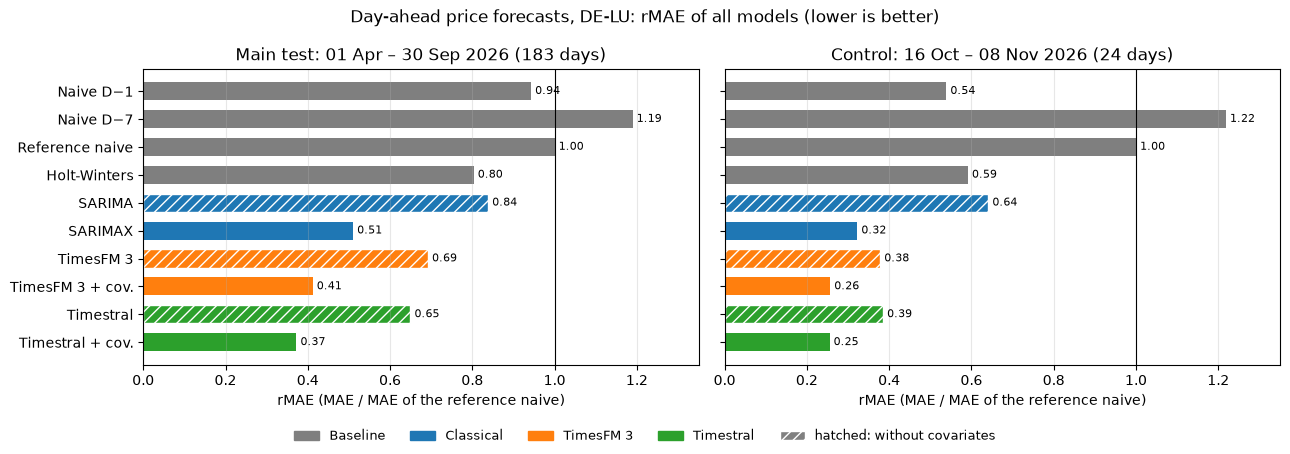

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
order = list(MODELS)[::-1]  # barh draws from the bottom: reversed so that the naives are at the top
for ax, period in zip(axes, PERIODS):
    rmae = table[(period, "rMAE")].reindex([LABELS[n] for n in order])
    colors = [FAMILY_COLORS[MODELS[n][1]] for n in order]
    bars = ax.barh(rmae.index, rmae.to_numpy(), color=colors, height=0.65)
    for bar, name in zip(bars, order):
        if MODELS[name][1] != "Baseline" and not MODELS[name][2]:
            bar.set_hatch("///")  # no covariates
            bar.set_edgecolor("white")
    for y, v in enumerate(rmae):
        ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
    ax.axvline(1, color="k", lw=0.8)
    ax.set_xlim(0, 1.35)
    ax.set_xlabel("rMAE (MAE / MAE of the reference naive)")
    days = PERIODS[period][0]
    ax.set_title(f"{period.capitalize()}: {days[0]:%d %b} – {days[-1]:%d %b %Y} ({len(days)} days)")
    ax.grid(axis="x", alpha=0.3)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAMILY_COLORS.values()]
handles.append(plt.Rectangle((0, 0), 1, 1, facecolor="grey", hatch="///", edgecolor="white"))
fig.legend(handles, [*FAMILY_COLORS, "hatched: without covariates"], loc="lower center", ncol=5, fontsize=9,
           frameon=False)
fig.suptitle("Day-ahead price forecasts, DE-LU: rMAE of all models (lower is better)")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(cfg.FIGURES_DIR / "results_rmae_all_models.png", dpi=150)
plt.show()

**Observations (main test).**
- **The three models with covariates come first**: Timestral + cov. (MAE 13.0 EUR/MWh, rMAE 0.37), TimesFM 3 + cov. (14.4, 0.41), SARIMAX (17.9, 0.51). Each of them beats every model without covariates.
- **Without covariates, the foundation models are the best**: Timestral (22.8, rMAE 0.65) and TimesFM 3 (24.3, 0.69) are ahead of Holt-Winters (28.2) and SARIMA (29.4), but far behind SARIMAX.
- **RMSE gives the same order.** RMSE is about 1.6 to 2 times the MAE for every model: the errors are heavy-tailed (price spikes, deep negative hours), see section 4.
- **Pinball loss**: Timestral + cov. 5.2, TimesFM 3 + cov. 5.8 EUR/MWh. The covariates reduce it by about 40 % for both models, as they reduce the MAE.

**Control period** (24 days, 16 October – 8 November 2026). The rMAE of every model is lower, because the reference naive is much worse there (MAE 73.3 against 35.0): 11 of the 24 days are forecast with D−7, which works badly in autumn, when the price level moves from week to week (`naive_d1` has rMAE 0.54). The MAE is the easier number to compare across periods: it increases for all models from the main test to the control period (e.g. SARIMAX 17.9 → 23.6, Timestral + cov. 13.0 → 18.7). The order is the same as on the main test, except that TimesFM 3 and Timestral are now close in both versions (27.7 vs 28.2 without covariates, 18.8 vs 18.7 with). With 24 days, differences of 1 or 2 EUR/MWh are not meaningful without a test. Diebold-Mariano tests and the contamination test come later in this notebook.

## 3. The two-way table

The research question (CLAUDE.md section 3) as a family × covariates table. A **row** gives the contribution of the covariates within a family; a **column** compares families with the same information (prices only, or prices + the same four known-future covariates). The covariate gain is the relative MAE reduction from the version without to the version with covariates.

In [ ]:
def two_way(period: str) -> pd.DataFrame:
    t = table[period]
    rows = {}
    for family, (without, with_cov) in TWO_WAY.items():
        a, b = t.loc[LABELS[without]], t.loc[LABELS[with_cov]]
        rows[family] = {
            ("MAE", "without cov."): a["MAE"], ("MAE", "with cov."): b["MAE"],
            ("rMAE", "without cov."): a["rMAE"], ("rMAE", "with cov."): b["rMAE"],
            ("covariate gain [%]", "MAE"): 100 * (1 - b["MAE"] / a["MAE"]),
        }
    return pd.DataFrame(rows).T


two_way_table = pd.concat({period: two_way(period) for period in PERIODS})
fmt = {c: "{:.3f}" if c[0] == "rMAE" else ("{:.0f} %" if c[0].startswith("covariate") else "{:.2f}")
       for c in two_way_table.columns}
display(two_way_table.style.format(fmt))
for period in PERIODS:
    t = table[period]
    print(f"{period}: reference naive MAE {t.loc['Reference naive', 'MAE']:.2f}, "
          f"Holt-Winters MAE {t.loc['Holt-Winters', 'MAE']:.2f} EUR/MWh")

main test: reference naive MAE 35.05, Holt-Winters MAE 28.15 EUR/MWh
control: reference naive MAE 73.29, Holt-Winters MAE 43.34 EUR/MWh


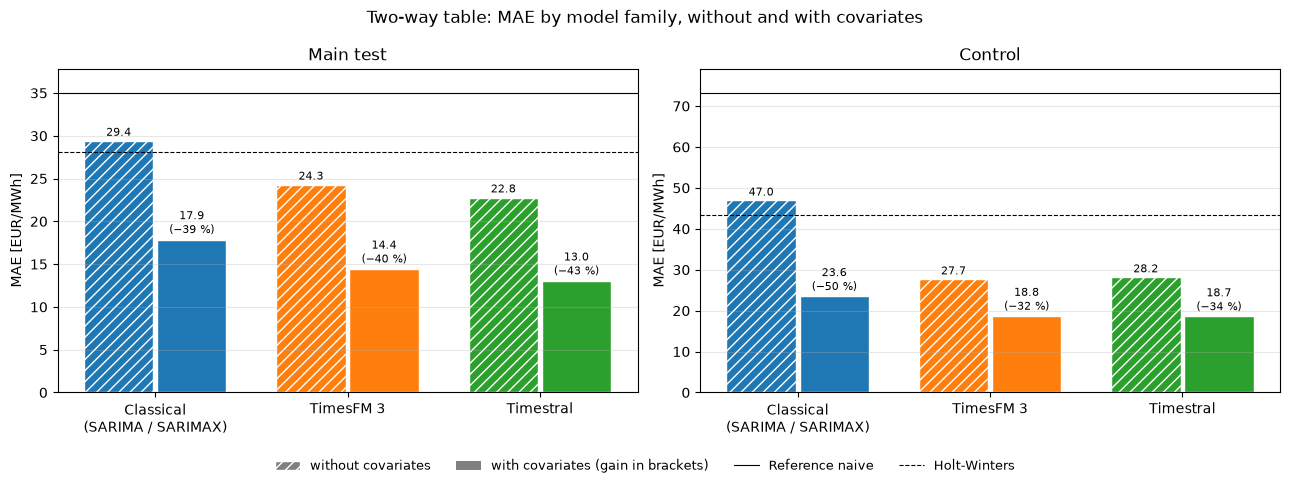

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
width = 0.38
for ax, period in zip(axes, PERIODS):
    t = two_way_table.loc[period]
    x = np.arange(len(t))
    colors = [FAMILY_COLORS[MODELS[TWO_WAY[f][1]][1]] for f in t.index]
    for k, (col, hatch) in enumerate([("without cov.", "///"), ("with cov.", None)]):
        values = t[("MAE", col)].to_numpy()
        positions = x + (k - 0.5) * width
        ax.bar(positions, values, width * 0.95, color=colors, hatch=hatch, edgecolor="white")
        for xi, v, gain in zip(positions, values, t[("covariate gain [%]", "MAE")]):
            label = f"{v:.1f}" if k == 0 else f"{v:.1f}\n(−{gain:.0f} %)"
            ax.text(xi, v + 0.01 * ax.get_ylim()[1], label, ha="center", va="bottom", fontsize=8)
    for name, ls in [("Reference naive", "-"), ("Holt-Winters", "--")]:
        ax.axhline(table.loc[name, (period, "MAE")], color="k", lw=0.8, ls=ls)
    ax.set_ylim(0, 1.08 * table.loc["Reference naive", (period, "MAE")])
    ax.set_xticks(x, ["Classical\n(SARIMA / SARIMAX)", "TimesFM 3", "Timestral"])
    ax.set_ylabel("MAE [EUR/MWh]")
    ax.set_title(period.capitalize())
    ax.grid(axis="y", alpha=0.3)
handles = [
    plt.Rectangle((0, 0), 1, 1, facecolor="grey", hatch="///", edgecolor="white"),
    plt.Rectangle((0, 0), 1, 1, facecolor="grey"),
    plt.Line2D([], [], color="k", lw=0.8, ls="-"),
    plt.Line2D([], [], color="k", lw=0.8, ls="--"),
]
fig.legend(handles, ["without covariates", "with covariates (gain in brackets)", "Reference naive", "Holt-Winters"],
           loc="lower center", ncol=4, fontsize=9, frameon=False)
fig.suptitle("Two-way table: MAE by model family, without and with covariates")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.savefig(cfg.FIGURES_DIR / "results_two_way_mae.png", dpi=150)
plt.show()

**Reading the rows: the contribution of the covariates.** On the main test, the covariates reduce the MAE by about **40 % in every family** (classical 39 %, TimesFM 3 40 %, Timestral 43 %). The relative gain does not depend much on the family. In absolute terms, SARIMA gains the most (−11.5 EUR/MWh), because it starts from the highest error. On the control period, the gain is larger for the classical family (50 %) than for the foundation models (32–34 %).

**Reading the columns: classical vs foundation models with the same information.**
- Prices only: TimesFM 3 and Timestral reduce the MAE of SARIMA by 17 % and 22 %.
- With the same four covariates: TimesFM 3 + cov. and Timestral + cov. reduce the MAE of SARIMAX by 19 % and 27 %.

The foundation models used zero-shot are therefore ahead of the course models in both columns, with Timestral slightly ahead of TimesFM 3 on the main test (by about 1.5 EUR/MWh in both columns).

**Across the diagonal**: SARIMAX (17.9) is much better than the univariate foundation models (22.8 and 24.3). On this task, adding the covariate forecasts to a course model brings more than replacing it with a foundation model that only sees the prices. The best result combines both.

Whether these differences are significant is tested with the Diebold-Mariano test in the next part of this notebook.

## 4. Forecasts vs actual prices on representative days

Three days of the main test, chosen by a fixed rule on the **actual** prices (for illustration only: nothing here feeds back into a model):

- **calm day**: the day with the lowest standard deviation of its 24 prices;
- **spike**: the day with the highest hourly price;
- **negative prices**: the day with the most hours below 0 EUR/MWh (ties broken by the lowest mean price).

For each day, one panel per family: the version without covariates (dashed) and with covariates (solid), and for the foundation models the 10–90 % band of each version (q10 … q90). The reference naive is drawn in grey in every panel for scale.

In [ ]:
main = res["main test"]
actual = main["naive_ref"].assign(t=lambda r: r["target_date"] + pd.to_timedelta(r["hour"], unit="h"))
daily = actual.groupby("target_date")["y_true"].agg(
    std="std", min="min", max="max", mean="mean", negative_hours=lambda s: int((s < 0).sum()))

examples = {
    "calm day": daily["std"].idxmin(),
    "spike": daily["max"].idxmax(),
    "negative prices": daily.sort_values(["negative_hours", "mean"], ascending=[False, True]).index[0],
}
info = daily.loc[list(examples.values())].round(1)
info.insert(0, "example", list(examples))
info.insert(1, "weekday", info.index.day_name())
info["non_working_day"] = df.loc[info.index, "non_working_day"].to_numpy()
info["mean wind_fc [GW]"] = [df.loc[d : d + pd.Timedelta(hours=23), "wind_fc"].mean().round(1) for d in info.index]
info["mean solar_fc [GW]"] = [df.loc[d : d + pd.Timedelta(hours=23), "solar_fc"].mean().round(1) for d in info.index]
info

,example,weekday,std,min,max,mean,negative_hours,non_working_day,mean wind_fc [GW],mean solar_fc [GW]
target_date,,,,,,,,,,
2026-05-11,calm day,Monday,15.6,96.0,154.0,119.3,0,0,16.8,7.5
2026-09-14,spike,Monday,126.1,161.4,697.3,256.5,0,0,3.2,10.4
2026-04-05,negative prices,Sunday,40.4,-105.2,33.4,-16.3,18,1,39.5,11.1


In [ ]:
def day_mae(name: str, day: pd.Timestamp) -> float:
    r = main[name][main[name]["target_date"] == day]
    return mae(r["y_true"], r["y_pred"])


day_table = pd.DataFrame({
    f"{example} ({day:%a %d %b})": {LABELS[name]: day_mae(name, day) for name in MODELS}
    for example, day in examples.items()
})
day_table.round(1).rename_axis("MAE [EUR/MWh]")

,calm day (Mon 11 May),spike (Mon 14 Sep),negative prices (Sun 05 Apr)
MAE [EUR/MWh],,,
Naive D−1,48.5,90.4,49.4
Naive D−7,26.8,100.7,86.7
Reference naive,26.8,100.7,86.7
Holt-Winters,26.4,83.8,39.1
SARIMA,38.5,110.3,75.6
SARIMAX,14.3,52.8,15.8
TimesFM 3,22.2,74.5,60.0
TimesFM 3 + cov.,13.7,47.4,23.8
Timestral,30.4,61.6,50.5


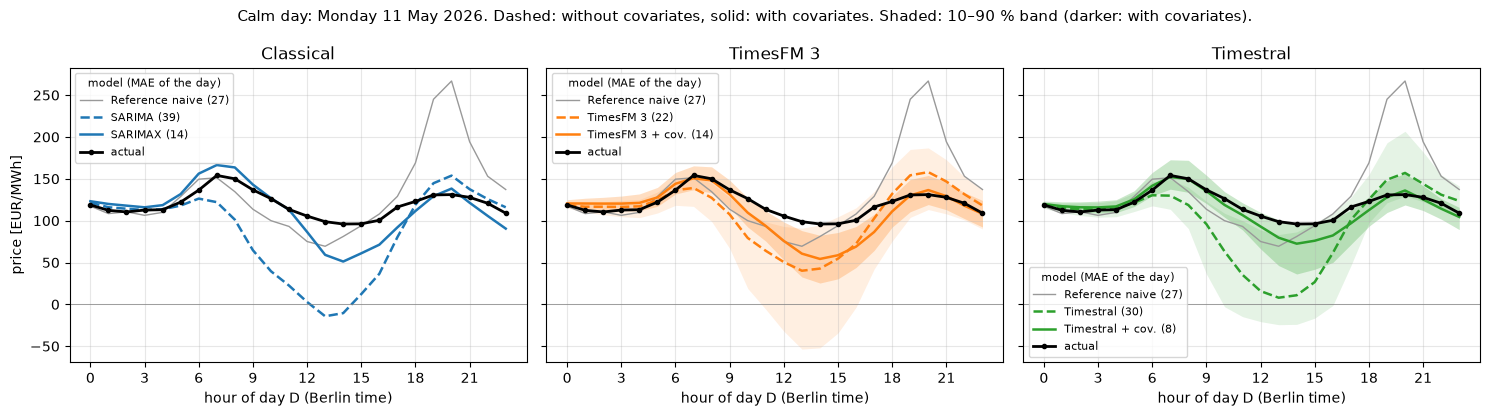

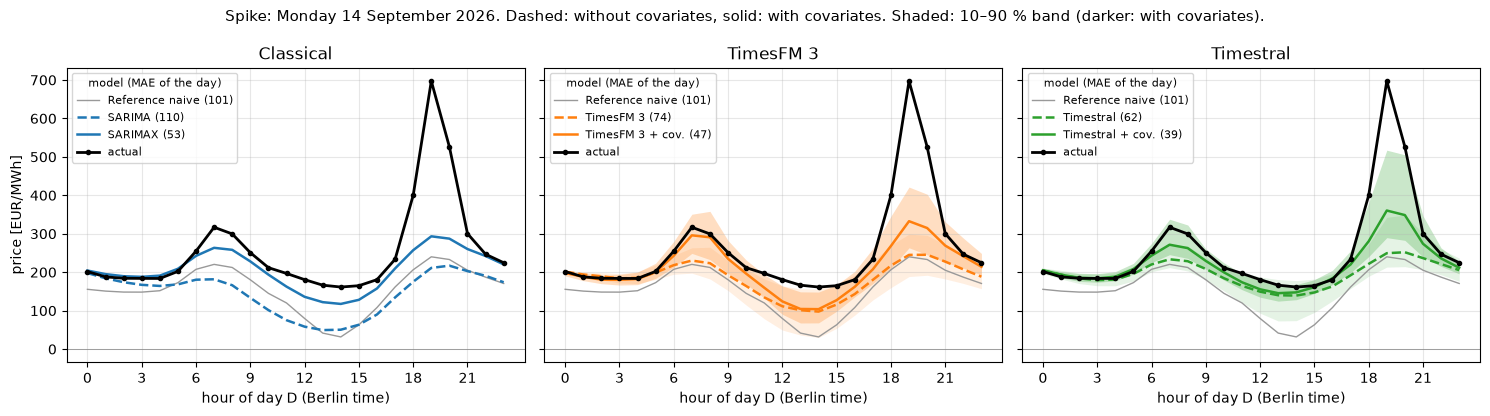

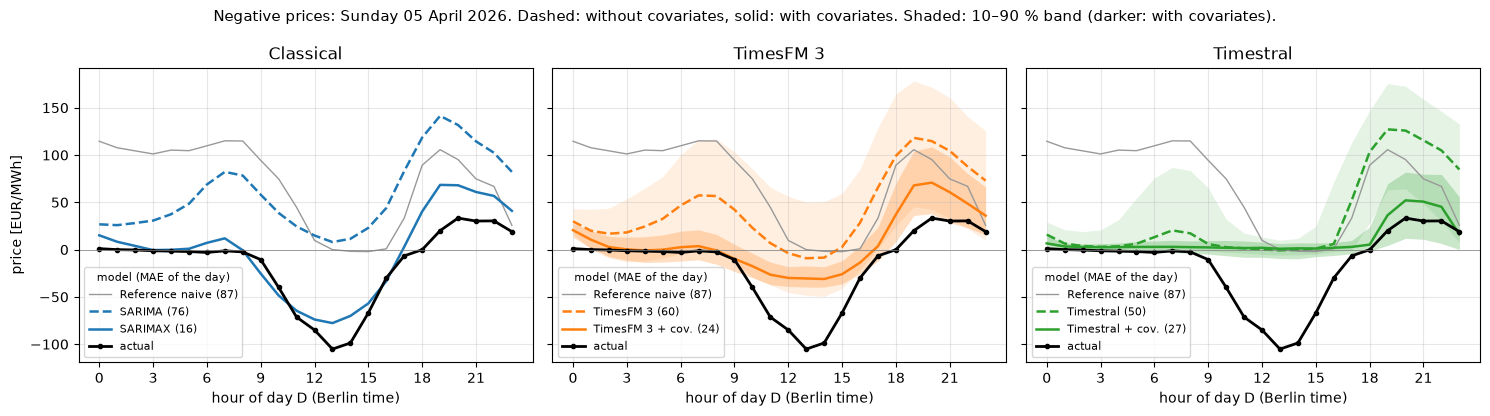

In [ ]:
PANELS = [("Classical", "sarima", "sarimax"), ("TimesFM 3", "timesfm", "timesfm_cov"),
          ("Timestral", "timestral", "timestral_cov")]
hours = np.arange(cfg.HORIZON)

for example, day in examples.items():
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
    y_true = main["naive_ref"].loc[main["naive_ref"]["target_date"] == day, "y_true"].to_numpy()
    for ax, (family, without, with_cov) in zip(axes, PANELS):
        color = FAMILY_COLORS[family]
        ref = main["naive_ref"][main["naive_ref"]["target_date"] == day]
        ax.plot(hours, ref["y_pred"], color="0.6", lw=1, label=f"{LABELS['naive_ref']} ({day_mae('naive_ref', day):.0f})")
        for name, ls, alpha in [(without, "--", 0.12), (with_cov, "-", 0.25)]:
            r = main[name][main[name]["target_date"] == day]
            if name in PROBABILISTIC:
                ax.fill_between(hours, r["q10"], r["q90"], color=color, alpha=alpha, lw=0)
            ax.plot(hours, r["y_pred"], color=color, ls=ls, lw=1.8, label=f"{LABELS[name]} ({day_mae(name, day):.0f})")
        ax.plot(hours, y_true, color="k", lw=2, marker="o", ms=3, label="actual")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_xticks(range(0, 24, 3))
        ax.set_xlabel("hour of day D (Berlin time)")
        ax.set_title(family)
        ax.legend(fontsize=8, title="model (MAE of the day)", title_fontsize=8, loc="best")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel("price [EUR/MWh]")
    bands = " Shaded: 10–90 % band (darker: with covariates)."
    fig.suptitle(f"{example.capitalize()}: {day:%A %d %B %Y}. Dashed: without covariates, solid: with covariates.{bands}",
                 fontsize=11)
    fig.tight_layout()
    fig.savefig(cfg.FIGURES_DIR / f"forecast_example_{example.replace(' ', '_')}.png", dpi=150)
    plt.show()

**Observations.**
- **Calm day** (Monday 11 May, the lowest intraday standard deviation of the test, 15.6 EUR/MWh). The main difficulty is the midday solar dip. The models without covariates forecast a deep dip, as on the previous days (SARIMA reaches −14 EUR/MWh at 13:00, Timestral univariate +8), while the actual price stays near 95. The reference naive copies the evening peak of the previous Monday (265 EUR/MWh), which does not happen. With the solar and wind forecasts, the dip becomes shallower, and Timestral + cov. follows the day closely (MAE 7.9).
- **Spike** (Monday 14 September, 697 EUR/MWh at 19:00, mean wind forecast 3.2 GW). No model reaches the spike. With covariates, all three models raise the evening peak (SARIMAX ≈ 290, TimesFM 3 + cov. ≈ 330, Timestral + cov. ≈ 360 EUR/MWh) and their error on the day is roughly halved. The 90 % quantile of Timestral + cov. goes up to ≈ 515 EUR/MWh: the band widens on the right hours but still misses the spike. Low wind is a necessary condition for such spikes, but the size of the spike also depends on gas prices and on the available capacity, which no model sees (CLAUDE.md section 10).
- **Negative prices** (Easter Sunday 5 April: 18 hours below 0, minimum −105 EUR/MWh, mean wind forecast 39.5 GW, the windiest day of the test). The models without covariates forecast an ordinary Sunday. **SARIMAX is the best model of the day** (MAE 15.8): its linear regression on wind and solar extrapolates down to −78 EUR/MWh. TimesFM 3 + cov. goes down to −31. Timestral + cov. stays at about 0 (lowest median +0.9, lowest q10 −10). This is not the non-negative clip, which is disabled (`clip_nonnegative=False`) and would not apply anyway, because the context contains negative prices. Over its 2,048 h context, the lowest price was only −11.8 EUR/MWh (47 negative hours), and the foundation models do not extrapolate much below the range of their context. Negative-price hours are analysed over the whole test in the detailed analyses.

## Summary so far

- All 10 models were evaluated on exactly the same 183 × 24 hours of the main test and 24 × 24 hours of the control period, against the same actual prices.
- **Covariates**: about −40 % MAE in every family on the main test (SARIMA → SARIMAX −39 %, TimesFM 3 −40 %, Timestral −43 %).
- **Foundation vs classical**: used zero-shot, TimesFM 3 and Timestral beat the course models in both columns of the table (−17 to −27 % MAE), and Timestral + cov. is the best model overall (MAE 13.0 EUR/MWh, rMAE 0.37). However, SARIMAX is better than the foundation models without covariates.
- **Failure cases**: no model forecasts the extreme evening spikes. On a deep negative-price day, the foundation models stay within the range of their context, while SARIMAX extrapolates through its regression on wind and solar.

Figures exported to `figures/`: `results_rmae_all_models.png`, `results_two_way_mae.png`, `forecast_example_calm_day.png`, `forecast_example_spike.png`, `forecast_example_negative_prices.png`.